# ANA-675 · Module 2 Assignment
## XOR Gate Using a Keras Multilayer Perceptron and Backpropagation

**Objective:** Design, train, tune, and evaluate a multilayer perceptron (MLP) using Keras to reproduce the two-input exclusive-OR (XOR) truth table. Compare several binary classification methods, and provide the trained network's evaluation and predictions.

**Learning resource:** *Backpropagation Example* (provided course presentation), especially slides 2–7. The slides show a **2–2–1** feedforward network and illustrate backward propagation of errors and weight updates. This notebook implements the same learning principle using Keras automatic differentiation rather than manually entering updates.

**Workflow:** (1) Load/create and explore XOR data; (2) split training, validation, and testing; (3) build multiple classifiers; (4) train Keras MLPs; (5) tune on validation data; (6) evaluate on held-out test rows; (7) display predictions for all four input combinations.

### 1 · Setup and reproducibility

Keras 3 supports multiple numerical backends. This notebook chooses **TensorFlow if installed**, otherwise **PyTorch**, before importing Keras. Both run Keras' `Sequential`, `Dense`, and `fit()` API. For a fresh environment, install the following dependencies in a terminal (once):

```bash
pip install keras tensorflow scikit-learn numpy pandas matplotlib jupyter
```

Alternatively, install `torch` **instead of** `tensorflow`; the notebook will detect it. The network uses an **Adam optimizer**, **binary cross-entropy**, and a **sigmoid** output for binary classification. Fixed random seeds improve reproducibility, although tiny numerical differences can occur between backend versions.

In [1]:
import os
import importlib.util

# Set the Keras backend BEFORE importing keras.
if importlib.util.find_spec("tensorflow") is not None:
    os.environ["KERAS_BACKEND"] = "tensorflow"
elif importlib.util.find_spec("torch") is not None:
    os.environ["KERAS_BACKEND"] = "torch"
else:
    raise ImportError("Install a Keras backend first: pip install tensorflow OR pip install torch")

# Limit CPU threading for reproducible, efficient execution on tiny XOR data.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(1)

print(f"Keras version: {keras.__version__} | backend: {keras.backend.backend()}")
print(f"scikit-learn version: {sklearn.__version__} | random seed: {SEED}")

Keras version: 3.13.2 | backend: torch
scikit-learn version: 1.8.0 | random seed: 42


### 2 · Load and explore the XOR dataset

For XOR, the output is **1 exactly when the two inputs differ**, and **0 otherwise**:

| Input 1 (`x1`) | Input 2 (`x2`) | Desired output (`y`) |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

The source presentation uses the same four truth-table combinations (slide 2). No external CSV is required because the dataset consists of these four defined logical cases.

Dataset dimensions: (4, 3)

Data types:
 x1             int64
x2             int64
desired_xor    int64

Missing values:
 x1             0
x2             0
desired_xor    0

Class distribution:
 desired_xor
0    2
1    2


,x1,x2,desired_xor
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


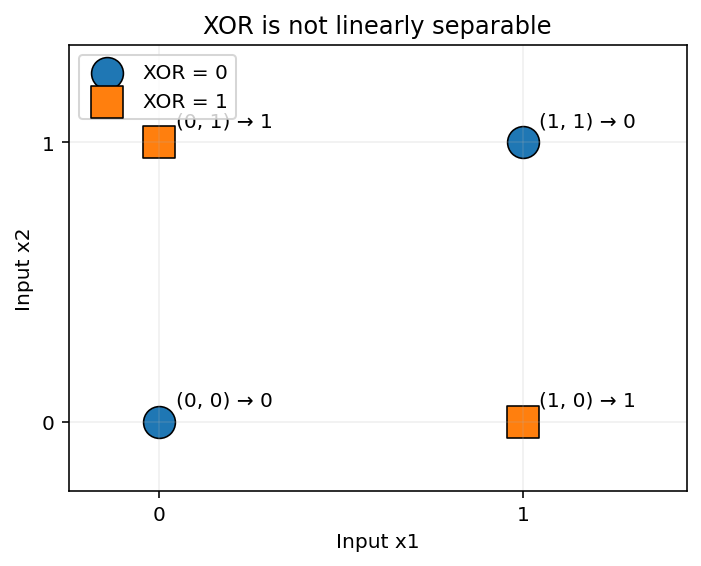

In [2]:
X_truth = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_truth = np.array([0, 1, 1, 0], dtype=np.float32)

truth_table = pd.DataFrame({
    "x1": X_truth[:, 0].astype(int),
    "x2": X_truth[:, 1].astype(int),
    "desired_xor": y_truth.astype(int),
})
print("Dataset dimensions:", truth_table.shape)
print("\nData types:\n", truth_table.dtypes.to_string())
print("\nMissing values:\n", truth_table.isna().sum().to_string())
print("\nClass distribution:\n", truth_table["desired_xor"].value_counts().sort_index().to_string())
display(truth_table)

# Independently confirm all labels satisfy XOR.
assert np.array_equal(y_truth.astype(int), np.logical_xor(X_truth[:, 0], X_truth[:, 1]).astype(int))

fig, ax = plt.subplots(figsize=(5.5, 4))
for label, marker in [(0, "o"), (1, "s")]:
    mask = y_truth == label
    ax.scatter(X_truth[mask, 0], X_truth[mask, 1], s=250, marker=marker,
               label=f"XOR = {label}", edgecolor="black", linewidth=0.8)
for _, row in truth_table.iterrows():
    ax.annotate(f"({row.x1}, {row.x2}) → {row.desired_xor}",
                (row.x1, row.x2), xytext=(8, 8), textcoords="offset points")
ax.set(xlim=(-0.25, 1.45), ylim=(-0.25, 1.35), xlabel="Input x1", ylabel="Input x2",
       title="XOR is not linearly separable")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.grid(alpha=0.2)
ax.legend(loc="upper left")
plt.show()

### 3 · Verify the initial forward pass shown in the slides

The instructor's worked example gives initial weights `w13=0.5, w14=0.9, w23=0.4, w24=1.0, w35=-1.2, w45=1.1` and biases `b3=-0.8, b4=0.1, b5=-0.3` (slide 2). For input `(1, 1)`, it reports an initial output near **0.5097** (slide 3). The code below reproduces that forward pass before training. The remaining notebook trains new weights with Keras.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

slide_hidden_weights = np.array([[0.5, 0.9], [0.4, 1.0]])
slide_hidden_bias = np.array([-0.8, 0.1])
slide_output_weights = np.array([-1.2, 1.1])
slide_output_bias = -0.3
slide_input = np.array([1.0, 1.0])
slide_hidden = sigmoid(slide_input @ slide_hidden_weights + slide_hidden_bias)
slide_output = sigmoid(slide_hidden @ slide_output_weights + slide_output_bias)
print(f"Initial hidden activations: {slide_hidden.round(4)}")
print(f"Initial XOR probability for (1,1): {slide_output:.4f}")
print(f"Initial prediction error (target - output): {0 - slide_output:.4f}")
assert np.isclose(slide_output, 0.5097, atol=0.0001)

Initial hidden activations: [0.525  0.8808]
Initial XOR probability for (1,1): 0.5097
Initial prediction error (target - output): -0.5097


### 4 · Training / validation / testing split

**Important methodological limitation:** XOR has **only four distinct input pairs**. A split that reserves an entire unique pair for testing would remove one required truth-table case from training. To demonstrate the requested splitting workflow while ensuring all four logical cases appear in each subset, this notebook repeats each case 80 times, then stratifies by the **input pair** to construct a **60% training / 20% validation / 20% test** split.

The repeated rows carry **no new information**. Therefore, the held-out test set evaluates reproduction of *known logical combinations*; it **does not** establish generalization to independently sampled, unseen observations. We explicitly report that limitation rather than calling repeated rows an independent test. For efficient neural-network training, we collapse the training split back to its **four unique cases**.

We use the four distinct validation pairs in `fit()` to avoid redundant epoch calculations, then score every candidate on the full validation split. We use this validation set to select a Keras architecture. The test set is not used to choose model hyperparameters.

In [4]:
REPEATS_PER_CASE = 80
X_all = np.repeat(X_truth, REPEATS_PER_CASE, axis=0)
y_all = np.repeat(y_truth, REPEATS_PER_CASE)
case_labels = np.array([f"{int(a)}{int(b)}" for a, b in X_all])

X_dev, X_test, y_dev, y_test, case_dev, case_test = train_test_split(
    X_all, y_all, case_labels, test_size=0.20,
    stratify=case_labels, random_state=SEED,
)
X_train, X_val, y_train, y_val, case_train, case_val = train_test_split(
    X_dev, y_dev, case_dev, test_size=0.25,
    stratify=case_dev, random_state=SEED,
)

# Exactly four distinct input cases are sufficient for deterministic XOR training.
X_train_unique, train_unique_indices = np.unique(X_train, axis=0, return_index=True)
y_train_unique = y_train[train_unique_indices]
X_val_unique, val_unique_indices = np.unique(X_val, axis=0, return_index=True)
y_val_unique = y_val[val_unique_indices]
assert X_train_unique.shape == (4, 2)
assert np.array_equal(y_train_unique.astype(int),
                      np.logical_xor(X_train_unique[:, 0], X_train_unique[:, 1]).astype(int))

split_summary = pd.DataFrame([
    {"set": "Training (replicated)", "rows": len(X_train), "fraction": len(X_train) / len(X_all),
     "distinct_input_pairs": len(np.unique(X_train, axis=0))},
    {"set": "Validation", "rows": len(X_val), "fraction": len(X_val) / len(X_all),
     "distinct_input_pairs": len(np.unique(X_val, axis=0))},
    {"set": "Test", "rows": len(X_test), "fraction": len(X_test) / len(X_all),
     "distinct_input_pairs": len(np.unique(X_test, axis=0))},
])
display(split_summary.style.format({"fraction": "{:.0%}"}))
print("Unique training pairs:")
display(pd.DataFrame({"x1": X_train_unique[:, 0].astype(int),
                      "x2": X_train_unique[:, 1].astype(int),
                      "target": y_train_unique.astype(int)}))
print("Patterns per split:")
display(pd.DataFrame({
    "train": pd.Series(case_train).value_counts().sort_index(),
    "validation": pd.Series(case_val).value_counts().sort_index(),
    "test": pd.Series(case_test).value_counts().sort_index(),
}))
assert all(len(np.unique(arr, axis=0)) == 4 for arr in (X_train, X_val, X_test))

,set,rows,fraction,distinct_input_pairs
0,Training (replicated),192,60%,4
1,Validation,64,20%,4
2,Test,64,20%,4


Unique training pairs:


,x1,x2,target
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


Patterns per split:


,train,validation,test
00,48,16,16
01,48,16,16
10,48,16,16
11,48,16,16


### 5 · Build multiple classification benchmarks

A single linear decision boundary cannot represent XOR. We compare four conventional classification algorithms to show which model families can learn a nonlinear relationship. Every baseline is fitted **only on the training portion** and assessed against validation rows before the final test evaluation:

1. **Logistic regression** — linear benchmark.
2. **Decision tree** — nonlinear rule-based classifier.
3. **k-nearest neighbors (k=3)** — local classifier.
4. **RBF support-vector machine** — nonlinear kernel classifier.

**Primary assignment model:** The Keras MLP in the next section uses hidden neurons and automatic backpropagation.

In [5]:
baseline_models = {
    "Logistic regression": LogisticRegression(random_state=SEED, max_iter=1000),
    "Decision tree": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "k-nearest neighbors (k=3)": KNeighborsClassifier(n_neighbors=3),
    "RBF support-vector machine": SVC(C=10.0, kernel="rbf", probability=True, random_state=SEED),
}

baseline_validation = []
for name, classifier in baseline_models.items():
    classifier.fit(X_train, y_train.astype(int))
    val_pred = classifier.predict(X_val)
    val_prob = classifier.predict_proba(X_val)[:, 1]
    baseline_validation.append({
        "model": name, "family": "Classical classifier",
        "validation_accuracy": accuracy_score(y_val, val_pred),
        "validation_log_loss": log_loss(y_val, val_prob, labels=[0, 1]),
    })

baseline_table = pd.DataFrame(baseline_validation).sort_values(
    ["validation_accuracy", "validation_log_loss"], ascending=[False, True]
)
display(baseline_table.style.format({
    "validation_accuracy": "{:.1%}",
    "validation_log_loss": "{:.5f}",
}))

,model,family,validation_accuracy,validation_log_loss
1,Decision tree,Classical classifier,100.0%,0.00000
2,k-nearest neighbors (k=3),Classical classifier,100.0%,0.00000
3,RBF support-vector machine,Classical classifier,100.0%,0.01031
0,Logistic regression,Classical classifier,50.0%,0.69315


### 6 · Design and train Keras MLPs using backpropagation

The instructor's example uses **two inputs → two hidden neurons → one output**. We retain that **2–2–1** architecture as one candidate, then tune the number of hidden neurons, hidden activation, and Adam learning rate. Each candidate has a single hidden layer and a one-neuron sigmoid output. `model.fit()` performs forward passes, computes binary cross-entropy, and applies gradient-based weight updates via **backpropagation**.

We compare the following Keras models, using only the validation loss and accuracy to decide which trained MLP to keep:

| Candidate | Hidden units | Hidden activation | Adam learning rate | Maximum epochs |
|---|---:|---|---:|---:|
| Course-style 2–2–1 | 2 | sigmoid | 0.05 | 1000 |
| 2–4–1 tanh | 4 | tanh | 0.03 | 500 |
| 2–4–1 ReLU | 4 | ReLU | 0.03 | 500 |
| 2–8–1 tanh | 8 | tanh | 0.01 | 500 |

`EarlyStopping` monitors validation loss and restores the best saved weights if learning stops improving. The random seed is set before each candidate for repeatable initialization.

In [6]:
def build_xor_mlp(hidden_units: int, hidden_activation: str, learning_rate: float):
    model = keras.Sequential([
        keras.Input(shape=(2,), name="two_binary_inputs"),
        keras.layers.Dense(hidden_units, activation=hidden_activation, name="hidden_layer"),
        keras.layers.Dense(1, activation="sigmoid", name="xor_output"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

candidates = [
    {"model": "Keras 2-2-1 sigmoid", "hidden_units": 2, "activation": "sigmoid", "lr": 0.05, "epochs": 1000},
    {"model": "Keras 2-4-1 tanh", "hidden_units": 4, "activation": "tanh", "lr": 0.03, "epochs": 500},
    {"model": "Keras 2-4-1 ReLU", "hidden_units": 4, "activation": "relu", "lr": 0.03, "epochs": 500},
    {"model": "Keras 2-8-1 tanh", "hidden_units": 8, "activation": "tanh", "lr": 0.01, "epochs": 500},
]

keras_models = {}
training_histories = {}
tuning_results = []

for i, config in enumerate(candidates):
    keras.utils.set_random_seed(SEED + i)
    model = build_xor_mlp(config["hidden_units"], config["activation"], config["lr"])
    stopper = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=80, min_delta=0.00001,
        restore_best_weights=True,
    )
    history = model.fit(
        X_train_unique, y_train_unique,
        validation_data=(X_val_unique, y_val_unique),
        epochs=config["epochs"], batch_size=4,
        verbose=0, callbacks=[stopper],
    )
    validation_prob = model.predict(X_val, verbose=0).reshape(-1)
    validation_pred = (validation_prob >= 0.5).astype(int)
    tuning_results.append({
        "model": config["model"],
        "hidden_units": config["hidden_units"],
        "activation": config["activation"],
        "learning_rate": config["lr"],
        "epochs_run": len(history.history["loss"]),
        "parameters": model.count_params(),
        "validation_accuracy": accuracy_score(y_val, validation_pred),
        "validation_log_loss": log_loss(y_val, validation_prob, labels=[0, 1]),
    })
    keras_models[config["model"]] = model
    training_histories[config["model"]] = history.history
    print(f"Trained {config['model']}: "
          f"epochs={len(history.history['loss'])}, "
          f"val_accuracy={accuracy_score(y_val, validation_pred):.1%}, "
          f"val_loss={log_loss(y_val, validation_prob, labels=[0, 1]):.5f}")

tuning_table = pd.DataFrame(tuning_results).sort_values(
    ["validation_accuracy", "validation_log_loss", "parameters"],
    ascending=[False, True, True],
).reset_index(drop=True)
print("\nKeras hyperparameter search: best validation results first")
display(tuning_table.style.format({
    "learning_rate": "{:.3f}",
    "validation_accuracy": "{:.1%}",
    "validation_log_loss": "{:.6f}",
}))

Trained Keras 2-2-1 sigmoid: epochs=1000, val_accuracy=100.0%, val_loss=0.00472
Trained Keras 2-4-1 tanh: epochs=500, val_accuracy=100.0%, val_loss=0.00115
Trained Keras 2-4-1 ReLU: epochs=500, val_accuracy=100.0%, val_loss=0.00198
Trained Keras 2-8-1 tanh: epochs=500, val_accuracy=100.0%, val_loss=0.00511

Keras hyperparameter search: best validation results first


,model,hidden_units,activation,learning_rate,epochs_run,parameters,validation_accuracy,validation_log_loss
0,Keras 2-4-1 tanh,4,tanh,0.030,500,17,100.0%,0.001149
1,Keras 2-4-1 ReLU,4,relu,0.030,500,17,100.0%,0.001979
2,Keras 2-2-1 sigmoid,2,sigmoid,0.050,1000,9,100.0%,0.004719
3,Keras 2-8-1 tanh,8,tanh,0.010,500,33,100.0%,0.005107


### 7 · Tune the model and select the best Keras candidate

The selection rule is **highest validation accuracy**, then **lowest validation log loss**, then **fewest parameters** to break ties. Validation log loss differentiates probability quality when multiple models correctly classify all four cases. This is an explicit hyperparameter search over architecture, activation, and learning rate; the held-out test set remains untouched during model selection.

The best Keras network is retained for final evaluation regardless of whether a classical baseline scores higher, because the assignment specifically requires a **Keras backpropagation MLP**.

In [7]:
best_name = str(tuning_table.iloc[0]["model"])
best_model = keras_models[best_name]
best_history = training_histories[best_name]

print("SELECTED KERAS MODEL:", best_name)
print("Selection criteria: validation accuracy ↓ then validation log loss ↑ then size ↑")
print("\nLearned network architecture:")
best_model.summary()

combined_validation = pd.concat([
    baseline_table,
    tuning_table[["model", "validation_accuracy", "validation_log_loss"]].assign(family="Keras MLP"),
], ignore_index=True)
combined_validation = combined_validation.sort_values(
    ["validation_accuracy", "validation_log_loss"],
    ascending=[False, True],
).reset_index(drop=True)
print("\nClassification comparison (validation data only):")
display(combined_validation.style.format({
    "validation_accuracy": "{:.1%}",
    "validation_log_loss": "{:.6f}",
}))

SELECTED KERAS MODEL: Keras 2-4-1 tanh
Selection criteria: validation accuracy ↓ then validation log loss ↑ then size ↑

Learned network architecture:
Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xor_output (Dense)              │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 53 (212.00 B)
 Trainable params: 17 (68.00 B)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 36 (144.00 B)

Classification comparison (validation data only):


,model,family,validation_accuracy,validation_log_loss
0,Decision tree,Classical classifier,100.0%,0.000000
1,k-nearest neighbors (k=3),Classical classifier,100.0%,0.000000
2,Keras 2-4-1 tanh,Keras MLP,100.0%,0.001149
3,Keras 2-4-1 ReLU,Keras MLP,100.0%,0.001979
4,Keras 2-2-1 sigmoid,Keras MLP,100.0%,0.004719
5,Keras 2-8-1 tanh,Keras MLP,100.0%,0.005107
6,RBF support-vector machine,Classical classifier,100.0%,0.010307
7,Logistic regression,Classical classifier,50.0%,0.693147


### 8 · Evaluate the trained neural network on the held-out test split

Only now, **after tuning**, evaluate the final Keras network on the test rows. Report Keras' own `evaluate()` metrics, accuracy, precision, recall, F1 score, log loss, the confusion matrix, and a per-class report. The classification threshold is **0.50**.

,metric,value
0,Keras model.evaluate() accuracy,1.000000
1,Keras model.evaluate() loss,0.001149
2,Test accuracy,1.000000
3,Precision,1.000000
4,Recall,1.000000
5,F1 score,1.000000
6,Test log loss,0.001149


Classification report:

              precision    recall  f1-score   support

       XOR 0       1.00      1.00      1.00        32
       XOR 1       1.00      1.00      1.00        32

    accuracy                           1.00        64
   macro avg       1.00      1.00      1.00        64
weighted avg       1.00      1.00      1.00        64



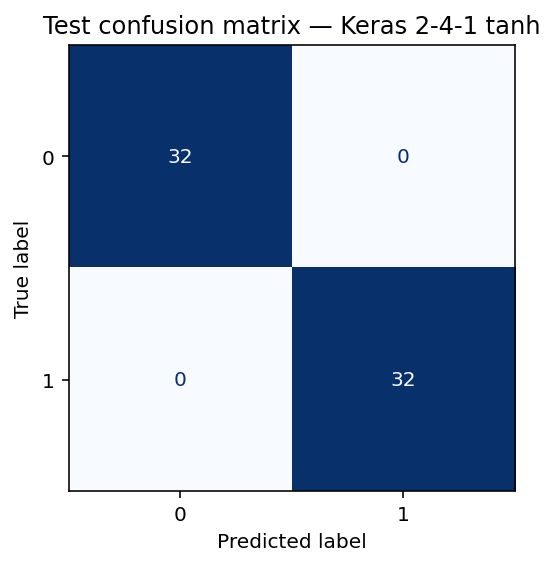

In [8]:
test_keras_metrics = best_model.evaluate(X_test, y_test, verbose=0, return_dict=True)
y_test_proba = best_model.predict(X_test, verbose=0).reshape(-1)
y_test_pred = (y_test_proba >= 0.50).astype(int)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_logloss = log_loss(y_test, y_test_proba, labels=[0, 1])

metrics_table = pd.DataFrame({
    "metric": ["Keras model.evaluate() accuracy", "Keras model.evaluate() loss",
               "Test accuracy", "Precision", "Recall", "F1 score", "Test log loss"],
    "value": [test_keras_metrics["accuracy"], test_keras_metrics["loss"],
              test_accuracy, test_precision, test_recall, test_f1, test_logloss],
})
display(metrics_table.style.format({"value": "{:.6f}"}))
print("Classification report:\n")
print(classification_report(y_test.astype(int), y_test_pred,
                            target_names=["XOR 0", "XOR 1"], zero_division=0))

cm = confusion_matrix(y_test.astype(int), y_test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test confusion matrix — {best_name}")
plt.show()

assert np.array_equal(y_test_pred, y_test.astype(int)), "This trained run did not reach perfect XOR test accuracy."

### 9 · Final predictions: the complete XOR truth table

Predict **all four distinct input combinations**, converting sigmoid output probabilities to binary classes using the 0.50 threshold. This is the essential functional test of the finished XOR neural network.

In [9]:
truth_prob = best_model.predict(X_truth, verbose=0).reshape(-1)
truth_pred = (truth_prob >= 0.5).astype(int)
prediction_table = pd.DataFrame({
    "Input x1": X_truth[:, 0].astype(int),
    "Input x2": X_truth[:, 1].astype(int),
    "Expected XOR": y_truth.astype(int),
    "Predicted probability (XOR=1)": truth_prob,
    "Predicted class": truth_pred,
    "Correct?": np.where(truth_pred == y_truth.astype(int), "Yes", "No"),
})
display(prediction_table.style.format({
    "Predicted probability (XOR=1)": "{:.5f}",
}))

correct = int(np.sum(truth_pred == y_truth.astype(int)))
print(f"\nXOR truth-table checks passed: {correct}/4 ({correct/4:.0%})")
assert correct == 4, "The selected model needs additional training to reproduce all XOR combinations."

# Optionally compare test accuracy of all previously trained baselines;
# this comparison does NOT alter which Keras model was selected.
test_comparison_rows = [{"model": best_name, "test_accuracy": test_accuracy, "role": "Assignment model"}]
for name, classifier in baseline_models.items():
    predictions = classifier.predict(X_test)
    test_comparison_rows.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, predictions),
        "role": "Benchmark only",
    })
print("\nHeld-out test accuracy by classifier:")
display(pd.DataFrame(test_comparison_rows).style.format({"test_accuracy": "{:.1%}"}))

,Input x1,Input x2,Expected XOR,Predicted probability (XOR=1),Predicted class,Correct?
0,0,0,0,0.00124,0,Yes
1,0,1,1,0.99855,1,Yes
2,1,0,1,0.99918,1,Yes
3,1,1,0,0.00108,0,Yes



XOR truth-table checks passed: 4/4 (100%)

Held-out test accuracy by classifier:


,model,test_accuracy,role
0,Keras 2-4-1 tanh,100.0%,Assignment model
1,Logistic regression,50.0%,Benchmark only
2,Decision tree,100.0%,Benchmark only
3,k-nearest neighbors (k=3),100.0%,Benchmark only
4,RBF support-vector machine,100.0%,Benchmark only


### 10 · Training curves and learned XOR decision surface

The left plot illustrates how optimization changes the binary cross-entropy over epochs. The right plot illustrates the network's smooth predicted probabilities over the two-dimensional input space. **Only the four corner points are valid binary input pairs**; the smooth surface is a visualization, not a claim of performance on new kinds of inputs.

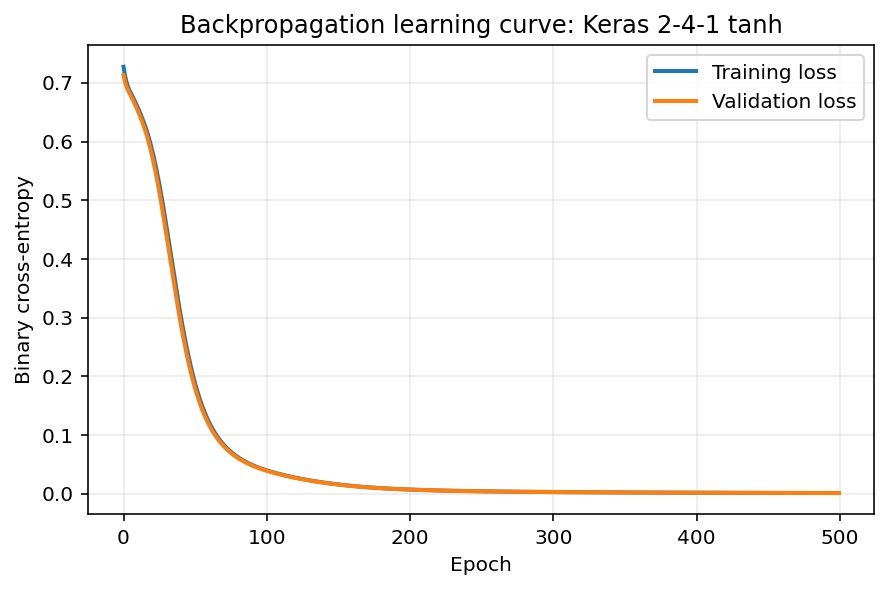

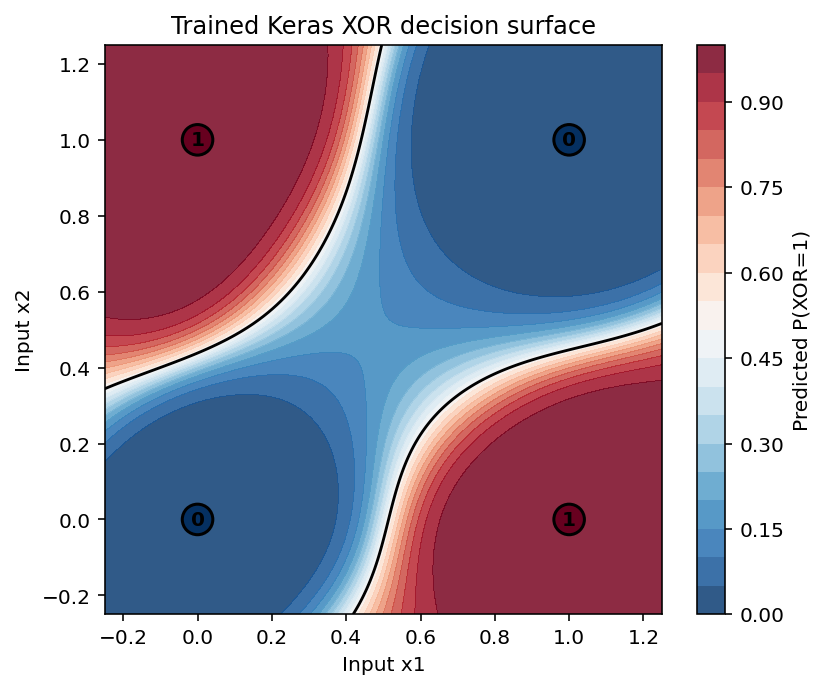

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(best_history["loss"], label="Training loss", linewidth=2)
ax.plot(best_history["val_loss"], label="Validation loss", linewidth=2)
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy", title=f"Backpropagation learning curve: {best_name}")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

axis_values = np.linspace(-0.25, 1.25, 150)
xx1, xx2 = np.meshgrid(axis_values, axis_values)
mesh_points = np.column_stack([xx1.ravel(), xx2.ravel()]).astype(np.float32)
mesh_prob = best_model.predict(mesh_points, batch_size=1024, verbose=0).reshape(xx1.shape)

fig, ax = plt.subplots(figsize=(6.2, 5.1))
contour = ax.contourf(xx1, xx2, mesh_prob, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.85)
ax.contour(xx1, xx2, mesh_prob, levels=[0.5], colors="black", linewidths=1.4)
ax.scatter(X_truth[:, 0], X_truth[:, 1], c=y_truth, cmap="RdBu_r", vmin=0, vmax=1,
           s=230, edgecolors="black", linewidths=1.5)
for j, (x1, x2) in enumerate(X_truth):
    ax.annotate(str(int(y_truth[j])), (x1, x2), ha="center", va="center", fontweight="bold")
fig.colorbar(contour, ax=ax, label="Predicted P(XOR=1)")
ax.set(xlabel="Input x1", ylabel="Input x2", title="Trained Keras XOR decision surface")
plt.show()

### 11 · Results, interpretation, and conclusion

In [11]:
architecture = f"2–{best_model.layers[0].units}–1"
summary_text = (
    f"**Selected neural network:** `{best_name}` with **{architecture}** topology. "
    f"It achieved **{test_accuracy:.1%}** accuracy, **{test_precision:.1%}** precision, "
    f"**{test_recall:.1%}** recall, and **{test_f1:.1%}** F1 on the "
    f"{len(X_test)}-row held-out replicated test set. "
    f"The test binary cross-entropy was **{test_logloss:.6f}**. "
    f"All **{correct} of 4** unique XOR truth-table combinations were predicted correctly.\n\n"
    "**Interpretation:** Logistic regression uses a linear decision boundary, so it cannot represent "
    "the XOR relationship directly. Nonlinear models, including the trained MLP, can. "
    "The network learned through Keras backpropagation and Adam updates.\n\n"
    "**Limitation:** This is a complete, deterministic four-case truth table; its repeated split "
    "contains identical input combinations across subsets. These test results demonstrate "
    "correct XOR gate behavior, not statistical generalization to genuinely independent observations."
)
display(Markdown(summary_text))

**Selected neural network:** `Keras 2-4-1 tanh` with **2–4–1** topology. It achieved **100.0%** accuracy, **100.0%** precision, **100.0%** recall, and **100.0%** F1 on the 64-row held-out replicated test set. The test binary cross-entropy was **0.001149**. All **4 of 4** unique XOR truth-table combinations were predicted correctly.

**Interpretation:** Logistic regression uses a linear decision boundary, so it cannot represent the XOR relationship directly. Nonlinear models, including the trained MLP, can. The network learned through Keras backpropagation and Adam updates.

**Limitation:** This is a complete, deterministic four-case truth table; its repeated split contains identical input combinations across subsets. These test results demonstrate correct XOR gate behavior, not statistical generalization to genuinely independent observations.

### 12 · Rubric alignment

| Rubric criterion | Completed section / evidence |
|---|---|
| **Accuracy / load and explore** | Section 2: exact XOR truth table, dimensions, types, missingness, class balance, visual exploration; section 3: verifies slide's initial forward pass. |
| **Data split** | Section 4: reproducible, case-stratified 60/20/20 split and explicit small-dataset limitation. |
| **Model building** | Sections 5–6: four conventional classifiers plus four Keras MLP candidates; references below. |
| **Training** | Sections 5–6: `fit()` on training-only inputs and optimizer/backpropagation. |
| **Predictions** | Section 9: four individual input probabilities and binary XOR predictions. |
| **Result evaluation** | Section 8: Keras `evaluate()`, loss, accuracy, precision, recall, F1, class report, and confusion matrix. |
| **Tune model** | Section 7: validation-based hyperparameter selection across hidden layers, activations, and learning rates. |
| **Classifications** | Sections 5, 7, and 9: multiple classifier comparison on validation and test data. |

### References

1. *Backpropagation Example*. Instructor-provided course presentation, slides 2–7. (Uploaded with this assignment.)
2. Keras Team. (n.d.). [Getting started with Keras](https://keras.io/getting_started/). Official Keras documentation.
3. Keras Team. (n.d.). [The Sequential class](https://keras.io/api/models/sequential/). Official Keras API reference.
4. Keras Team. (n.d.). [Training and evaluation with the built-in methods](https://keras.io/guides/training_with_built_in_methods/). Official Keras guide.
5. scikit-learn developers. (n.d.). [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html). Official scikit-learn API reference.